In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_dictionary.csv to data_dictionary.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving esports_gaming_biometrics_250k.csv to esports_gaming_biometrics_250k.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset utama
train = pd.read_csv("/content/esports_gaming_biometrics_250k.csv")

# Membaca data dictionary
data_dictionary = pd.read_csv("/content/data_dictionary.csv")

# Menampilkan 5 data pertama
train.head()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss


In [ ]:
data_dictionary.head()

,Column_Name,Description
0,Player_ID,A unique alphanumeric identifier for each gamer.
1,Age,"The age of the player, ranging from 16 to 40 y..."
2,Game_Genre,The category of the game played during the ses...
3,PlayTime_Hours,The duration of the current gaming session in ...
4,Sleep_Hours,The number of hours the player slept the night...


In [ ]:
# Melihat informasi dataset
train.info()

# Mengecek ukuran dataset
print("Ukuran dataset:", train.shape)

# Mengecek missing value
print("\nMissing Value:")
print(train.isnull().sum())

# Mengecek data duplikat
print("\nJumlah data duplikat:", train.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Player_ID          250000 non-null  object 
 1   Age                250000 non-null  int64  
 2   Game_Genre         250000 non-null  object 
 3   PlayTime_Hours     250000 non-null  float64
 4   Sleep_Hours        250000 non-null  float64
 5   Energy_Drinks      250000 non-null  int64  
 6   Screen_Brightness  237452 non-null  float64
 7   Blue_Light_Filter  250000 non-null  object 
 8   APM                250000 non-null  int64  
 9   Heart_Rate_BPM     250000 non-null  int64  
 10  HRV_Score          245066 non-null  float64
 11  Reaction_Time_ms   250000 non-null  float64
 12  Match_Outcome      250000 non-null  object 
dtypes: float64(5), int64(4), object(4)
memory usage: 24.8+ MB
Ukuran dataset: (250000, 13)

Missing Value:
Player_ID                0
Age                

In [ ]:
train = train.drop_duplicates()

print("Ukuran setelah menghapus duplikat:", train.shape)

Ukuran setelah menghapus duplikat: (250000, 13)


In [ ]:
categorical_features = train.select_dtypes(include=['object']).columns

for column in categorical_features:
    if train[column].isnull().sum() > 0:
        train[column] = train[column].fillna(train[column].mode()[0])

In [ ]:
numeric_features = train.select_dtypes(include=['number']).columns

for column in numeric_features:
    if train[column].isnull().sum() > 0:
        train[column] = train[column].fillna(train[column].median())

In [ ]:
from sklearn.preprocessing import LabelEncoder

df = train.copy()

categorical_features = df.select_dtypes(include=['object']).columns

label_encoder = LabelEncoder()

for column in categorical_features:
    df[column] = label_encoder.fit_transform(df[column].astype(str))

df.head()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,0,24,1,1.41,8.88,0,43.4,1,107,78,95.02,268.96,0
1,1,22,1,4.43,7.45,2,88.0,1,110,102,82.92,281.90,1
2,2,25,0,3.75,8.10,1,24.8,1,152,96,89.13,288.57,1
3,3,29,1,1.76,6.69,0,80.2,0,151,65,80.41,279.76,1
4,4,22,1,5.79,8.17,1,34.4,0,148,95,95.71,229.62,0


In [ ]:
# Statistik deskriptif
df.describe()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,124999.500000,22.588136,1.749716,2.527753,6.500900,0.917720,54.917794,0.350720,204.076168,84.062784,87.512854,262.900538,0.480624
std,72168.927986,3.829706,1.133906,2.358799,1.495851,1.045559,25.305955,0.477196,77.004233,9.670229,10.955971,19.096927,0.499625
min,0.000000,16.000000,0.000000,0.500000,2.000000,0.000000,10.000000,0.000000,30.000000,60.000000,25.510000,175.170000,0.000000
25%,62499.750000,20.000000,1.000000,0.720000,5.490000,0.000000,33.700000,0.000000,143.000000,77.000000,80.810000,249.930000,0.000000
50%,124999.500000,23.000000,1.000000,1.730000,6.500000,1.000000,54.900000,0.000000,192.000000,84.000000,89.190000,262.590000,0.000000
75%,187499.250000,25.000000,3.000000,3.470000,7.510000,1.000000,76.200000,1.000000,263.000000,90.000000,97.070000,275.600000,1.000000
max,249999.000000,40.000000,3.000000,12.000000,11.000000,4.000000,100.000000,1.000000,563.000000,129.000000,100.000000,355.470000,1.000000


In [ ]:
for column in categorical_features:
    print(f"\n{column}:")
    print(train[column].value_counts())


Player_ID:
Player_ID
PL_249984    1
PL_249983    1
PL_249982    1
PL_249981    1
PL_249980    1
            ..
PL_000005    1
PL_000004    1
PL_000003    1
PL_000002    1
PL_000001    1
Name: count, Length: 250000, dtype: int64

Game_Genre:
Game_Genre
MOBA             99887
FPS              87708
Battle Royale    37375
Fighting         25030
Name: count, dtype: int64

Blue_Light_Filter:
Blue_Light_Filter
No     162320
Yes     87680
Name: count, dtype: int64

Match_Outcome:
Match_Outcome
Loss    129844
Win     120156
Name: count, dtype: int64


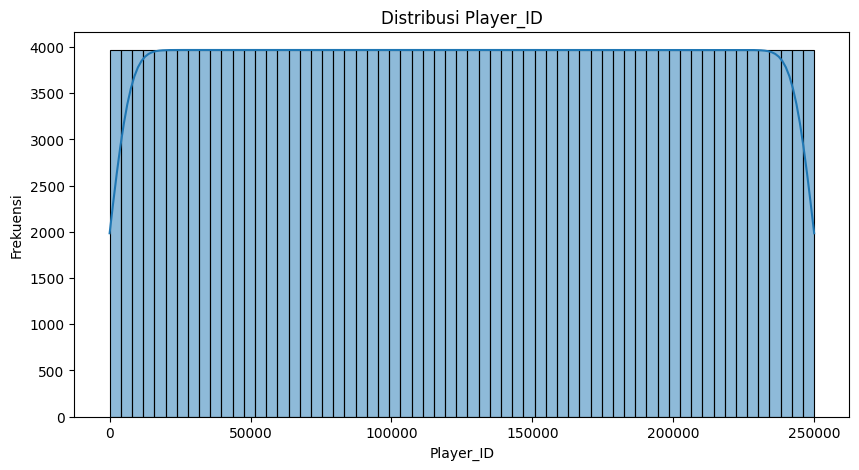

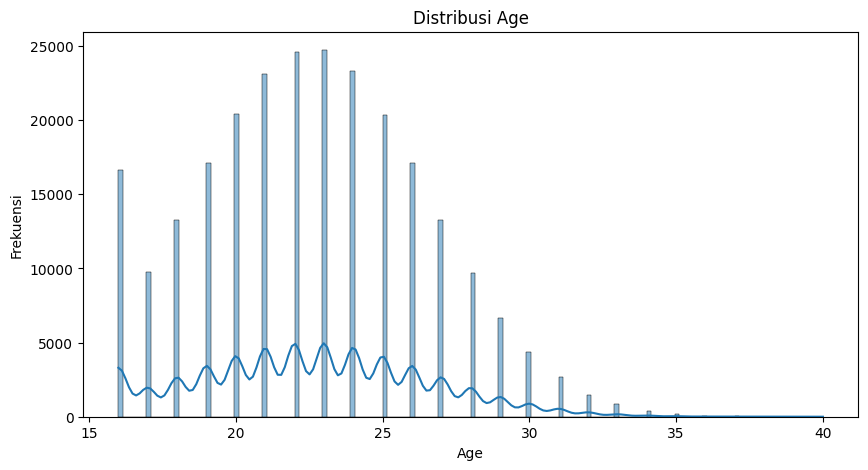

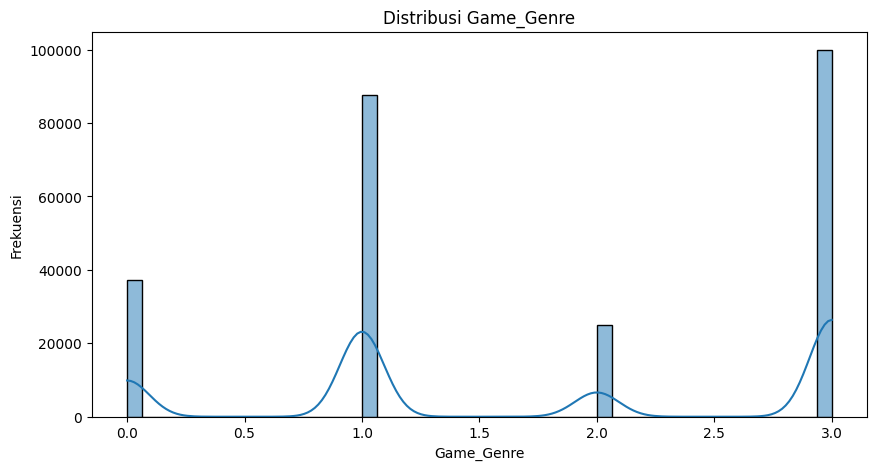

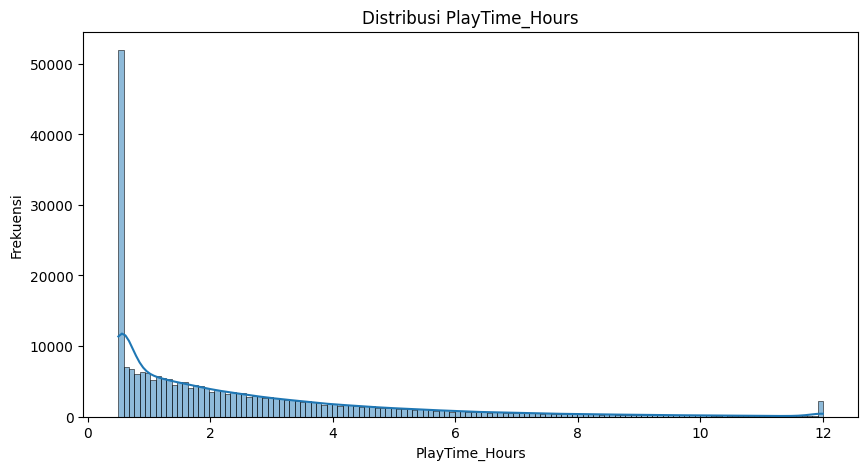

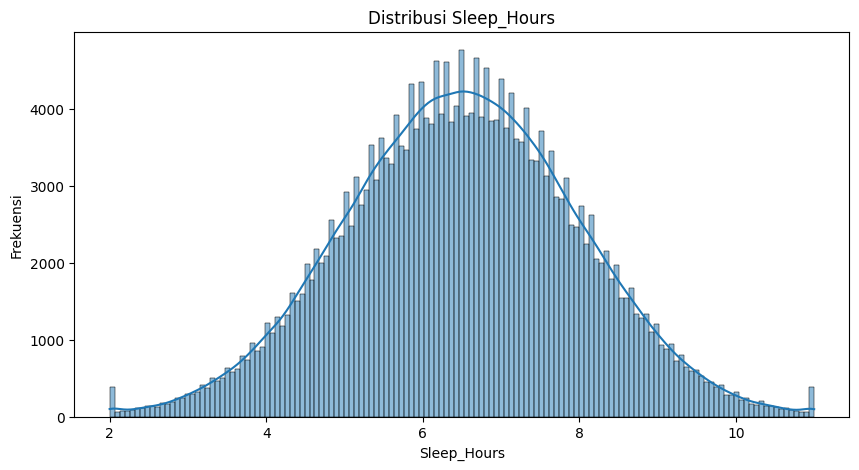

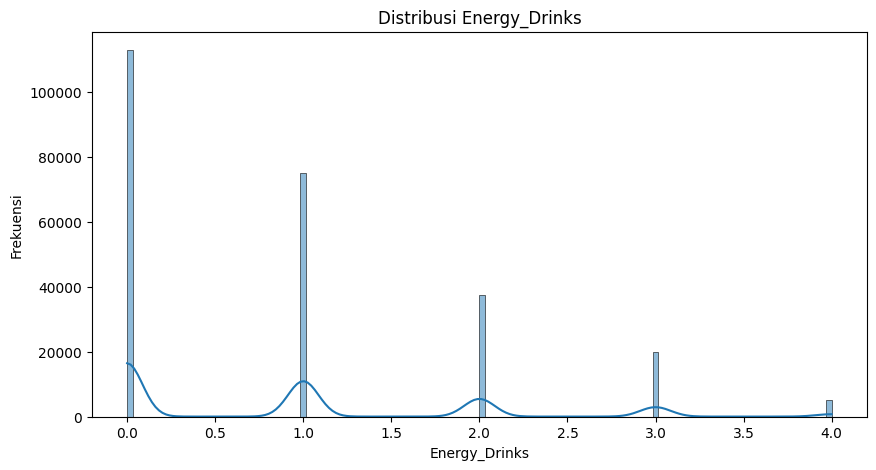

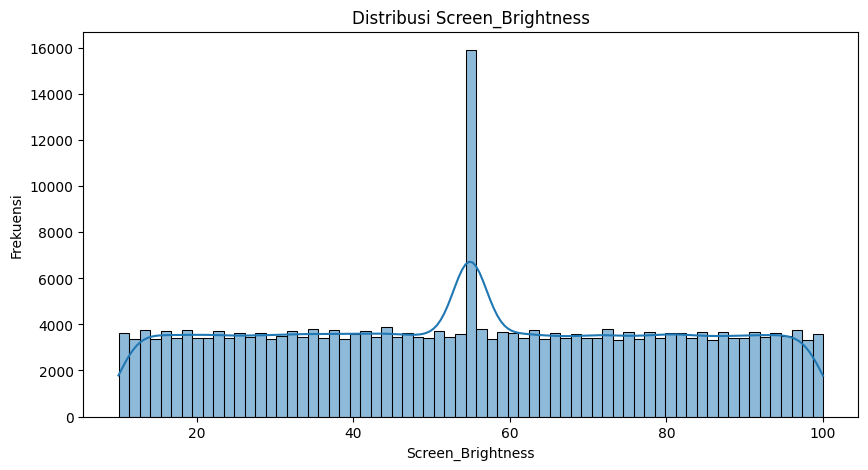

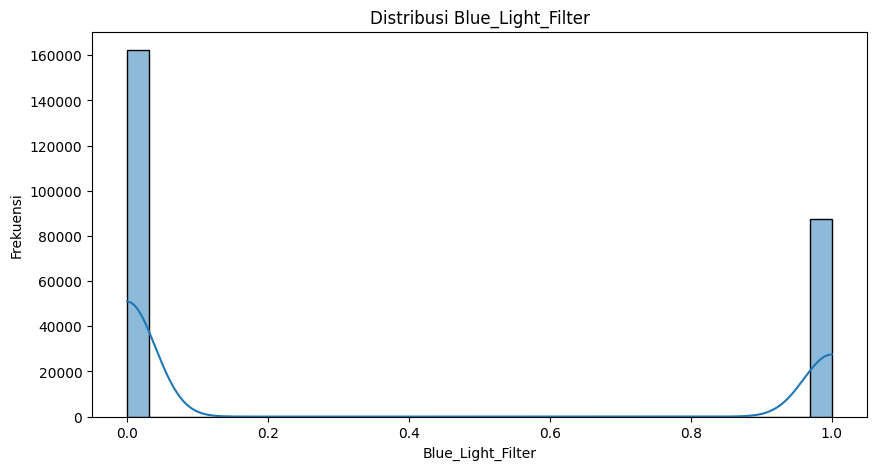

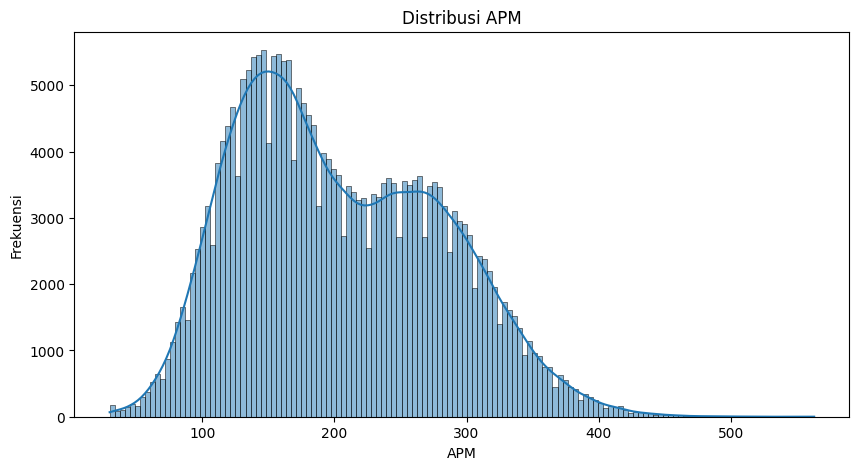

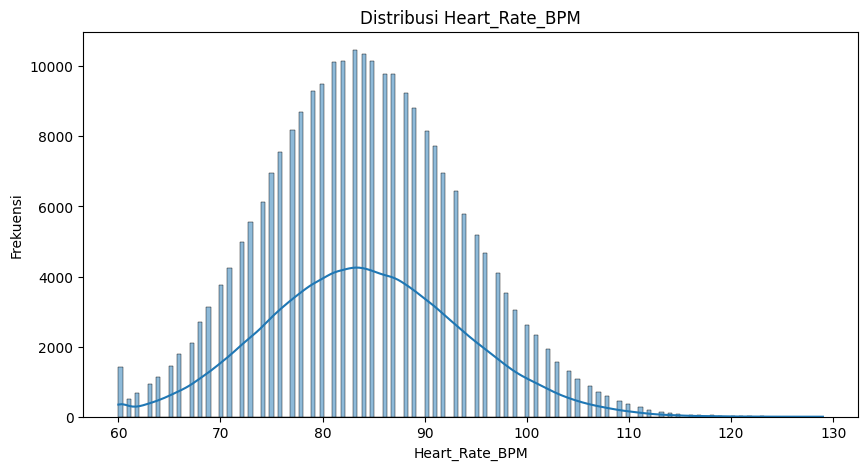

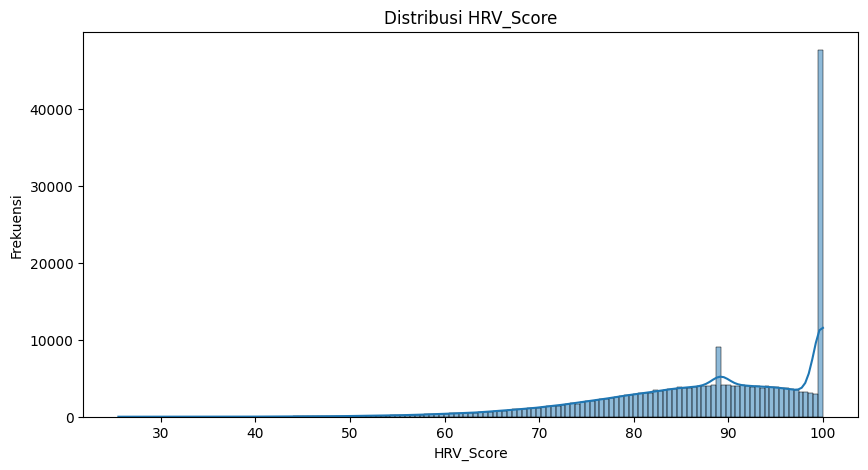

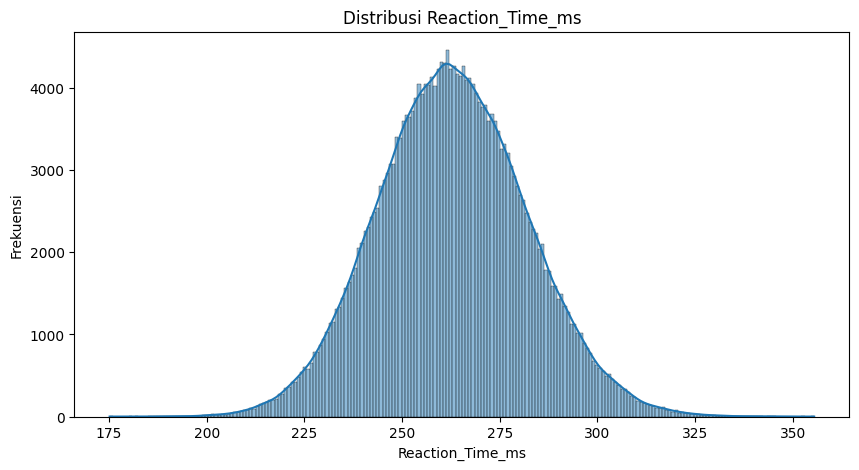

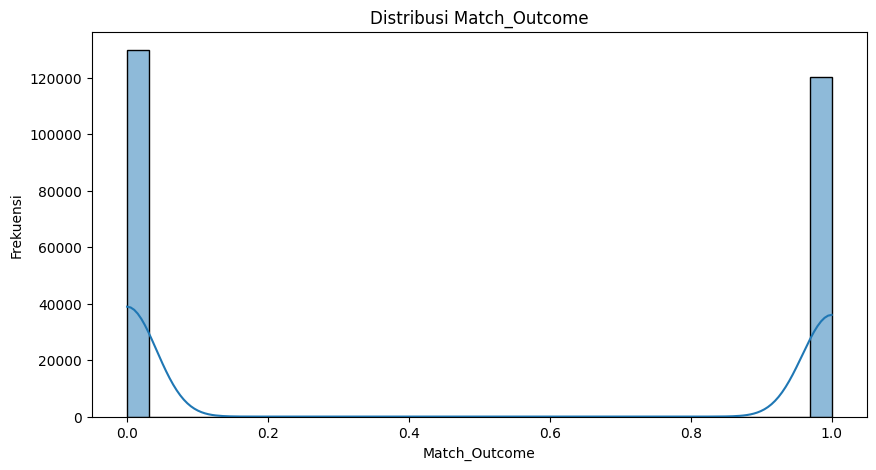

In [ ]:
numeric_features = df.select_dtypes(include=['number']).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribusi {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frekuensi')
    plt.show()

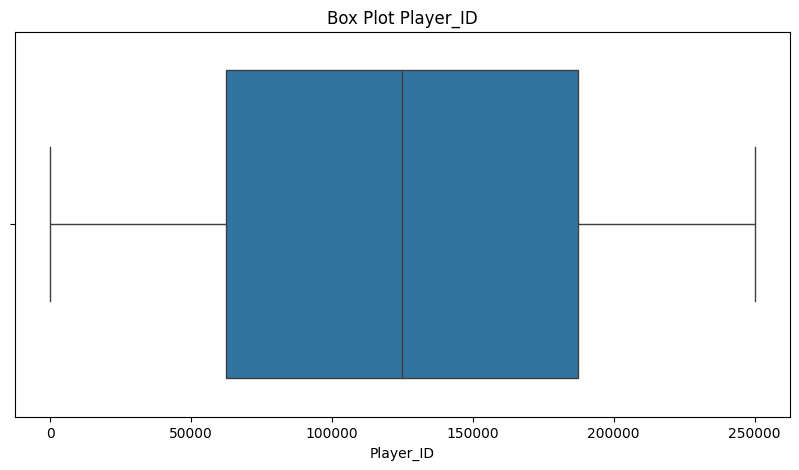

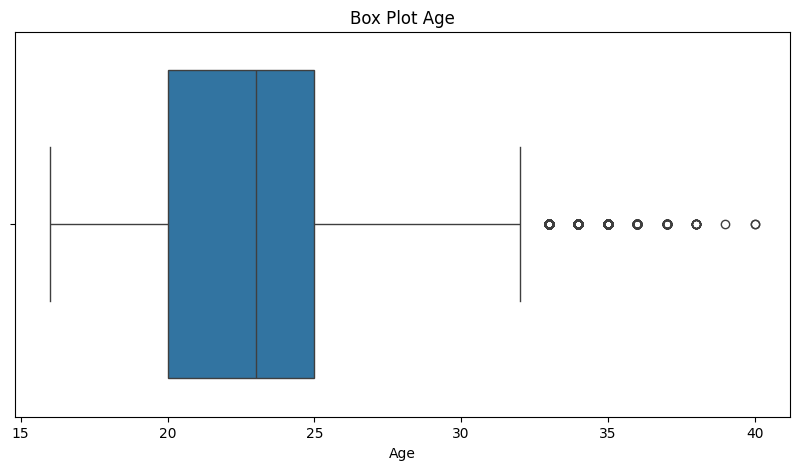

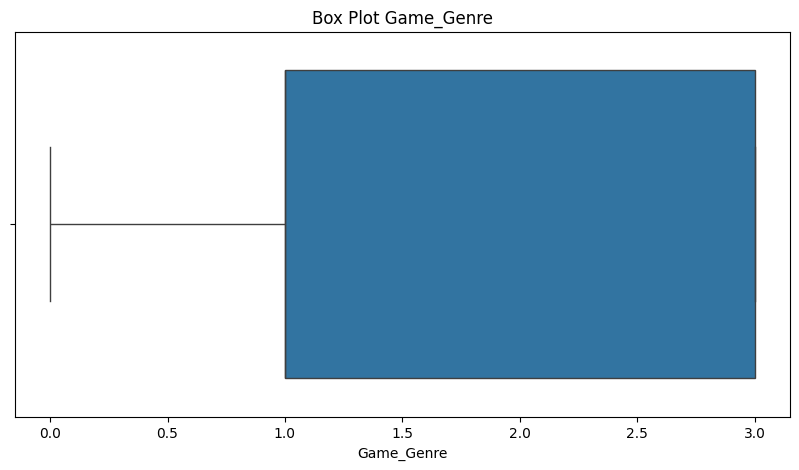

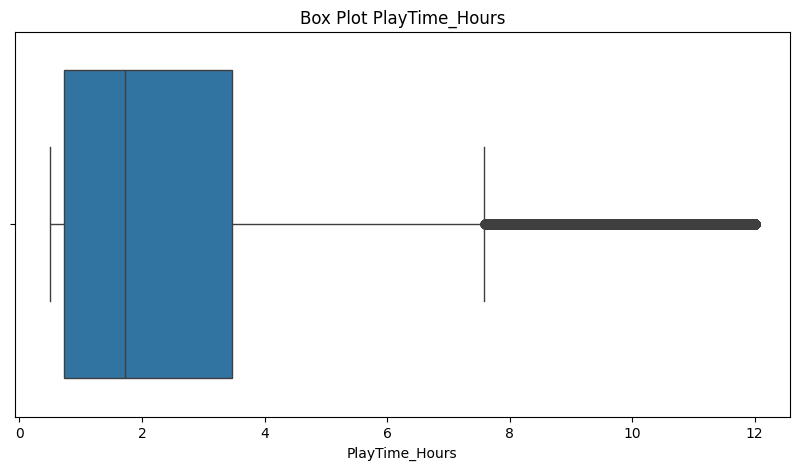

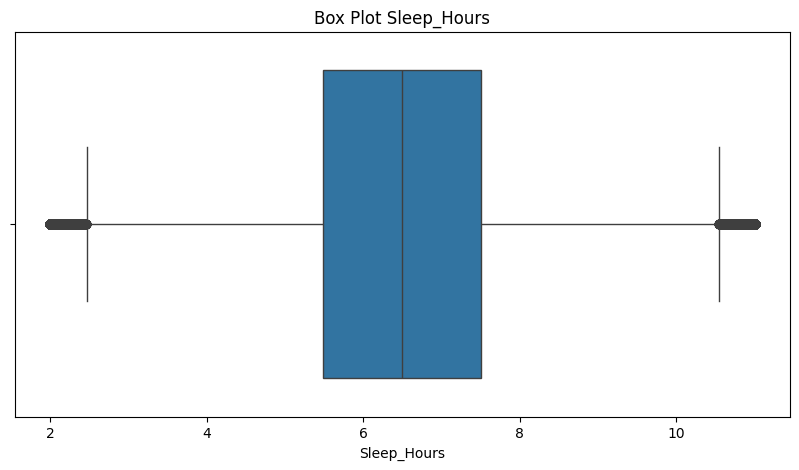

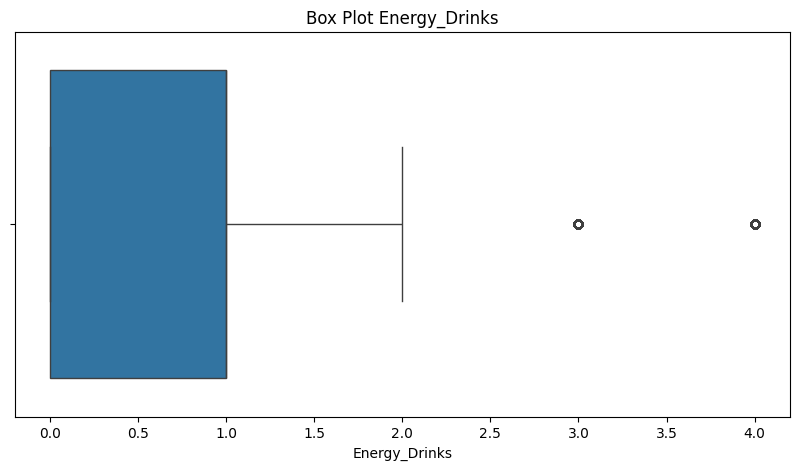

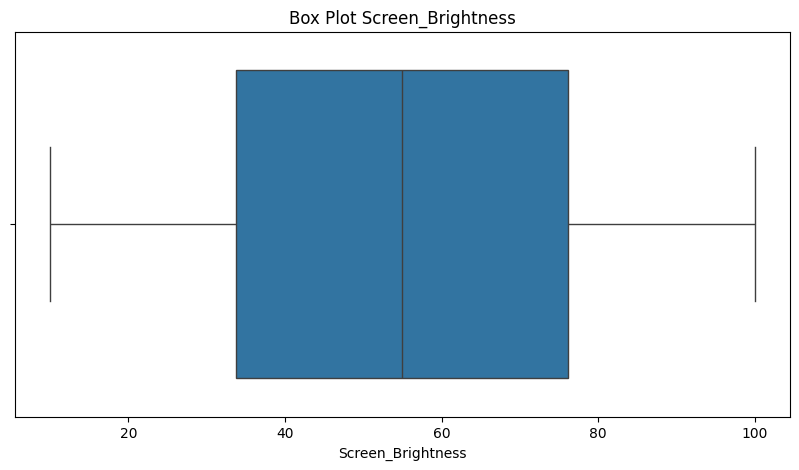

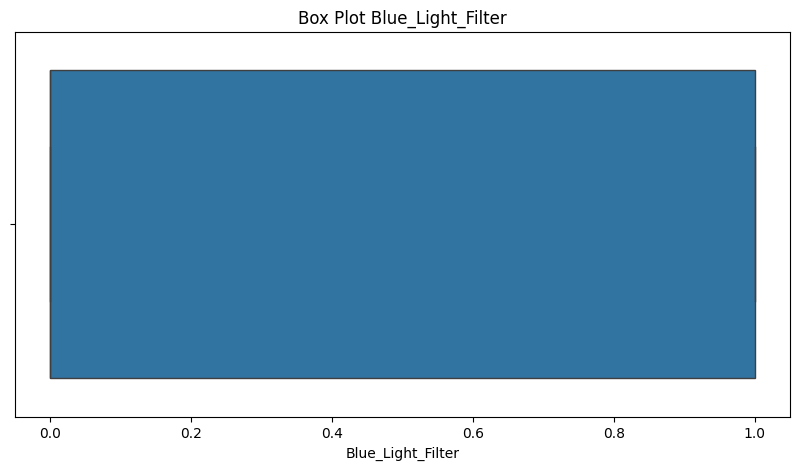

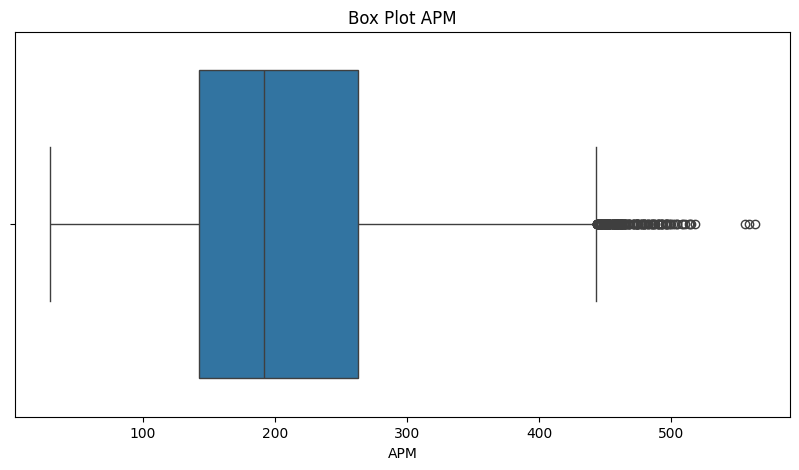

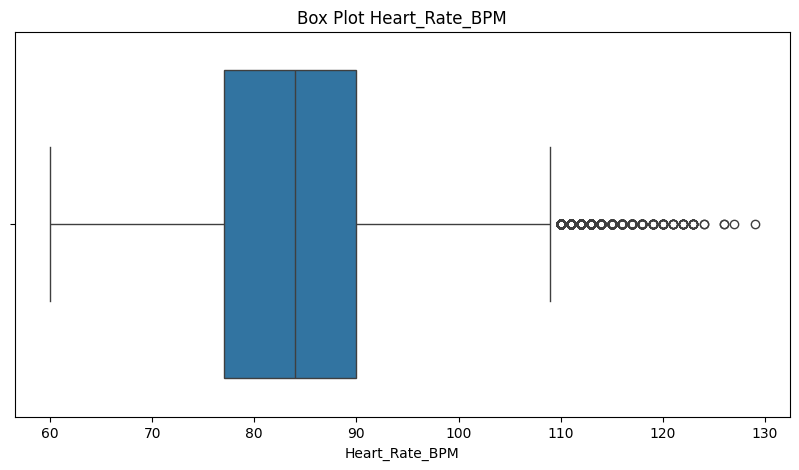

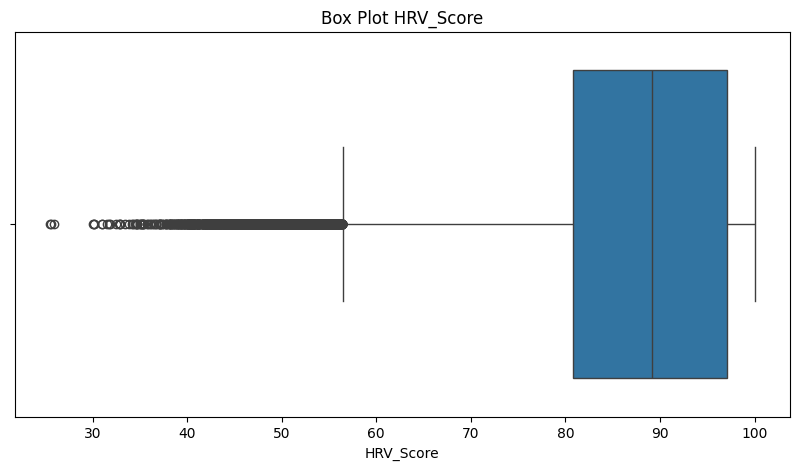

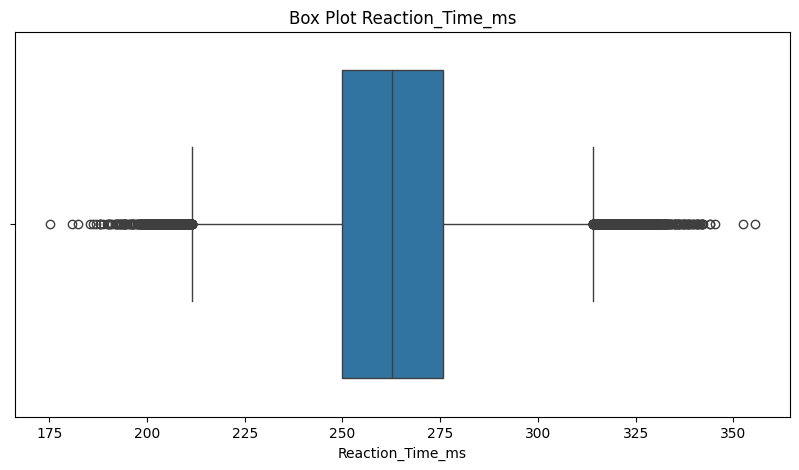

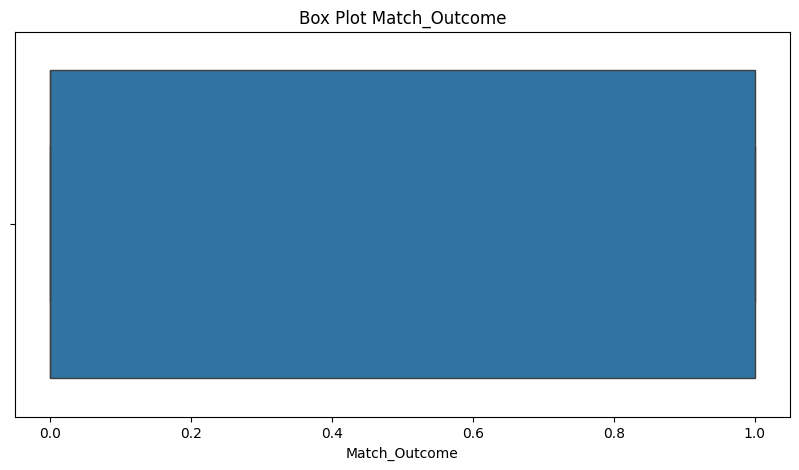

In [ ]:
for feature in numeric_features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot {feature}')
    plt.show()

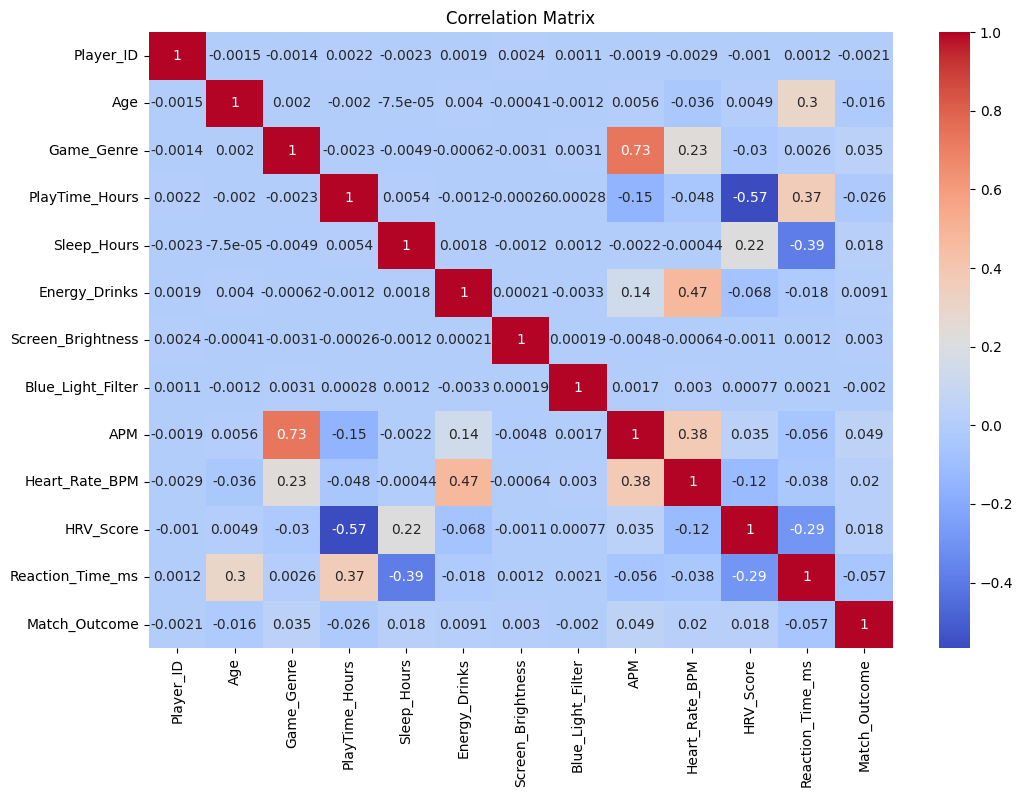

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Fitur
X = df.drop(columns=['Player_ID', 'Match_Outcome'])

# Target
y = df['Match_Outcome']

# Split 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

print("Jumlah data:", len(X))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data: 250000
Jumlah data training: 200000
Jumlah data testing: 50000


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_dictionary.csv to data_dictionary.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving esports_gaming_biometrics_250k.csv to esports_gaming_biometrics_250k.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'How to get started with Drive.pdf',
 'Classroom',
 'SURVIVAL LoLsKuY 1_16 SEASON 3.rar',
 'Tujuan negara (4 Sep 2020 3.28.36 PM).jpeg',
 'IMG_20200904_152706.jpg',
 'IMG_20200904_154301.jpg',
 'IMG_20200904_154721 (1).jpg',
 'IMG_20200904_154721.jpg',
 'IMG_20200914_112109.jpg',
 'IMG_20201104_093506.jpg',
 'IMG_20201125_103324.jpg',
 'IMG_20201125_103340.jpg',
 'Make a sentences of :\n1. Hope\n2. Wish\nWith the translate (25 Nov 2020 10.51.08 AM).jpeg',
 'IMG_20201125_132500.jpg',
 'IMG_20201125_132529.jpg',
 'IMG_20201125_140431.jpg',
 'IMG_20201125_140440.jpg',
 'IMG_20201125_140502.jpg',
 'RobloxScreenShot20201207_145400410.png',
 'RobloxScreenShot20201208_202904502.png',
 'RobloxScreenShot20201209_144918113.png',
 'RobloxScreenShot20201209_145233453.png',
 'RobloxScreenShot20201220_072206930.png',
 'RobloxScreenShot20201222_194509669.png',
 'RobloxScreenShot20201223_132320907.png',
 'RobloxScreenShot20201224_081557894.png',
 'RobloxScreenShot20201224_15152667

In [ ]:
import os

os.listdir('/content')

['.config',
 'data_dictionary.csv',
 'esports_gaming_biometrics_250k.csv',
 'drive',
 'sample_data']

In [ ]:
from google.colab import files
import shutil
import os

# Buat folder dataset di Google Drive
folder = '/content/drive/MyDrive/dataset'
os.makedirs(folder, exist_ok=True)

# Upload file
uploaded = files.upload()

# Pindahkan file ke Google Drive
for filename in uploaded.keys():
    shutil.move(filename, os.path.join(folder, filename))

print("File berhasil disimpan ke Google Drive!")

Saving data_dictionary.csv to data_dictionary (1).csv
File berhasil disimpan ke Google Drive!


In [ ]:
from google.colab import files
import shutil
import os

# Buat folder dataset di Google Drive
folder = '/content/drive/MyDrive/dataset'
os.makedirs(folder, exist_ok=True)

# Upload file
uploaded = files.upload()

# Pindahkan file ke Google Drive
for filename in uploaded.keys():
    shutil.move(filename, os.path.join(folder, filename))

print("File berhasil disimpan ke Google Drive!")

Saving esports_gaming_biometrics_250k.csv to esports_gaming_biometrics_250k (1).csv
File berhasil disimpan ke Google Drive!


In [ ]:
os.listdir('/content/drive/MyDrive/dataset')

['data_dictionary (1).csv', 'esports_gaming_biometrics_250k (1).csv']

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'How to get started with Drive.pdf', 'Classroom', 'SURVIVAL LoLsKuY 1_16 SEASON 3.rar', 'Tujuan negara (4 Sep 2020 3.28.36 PM).jpeg', 'IMG_20200904_152706.jpg', 'IMG_20200904_154301.jpg', 'IMG_20200904_154721 (1).jpg', 'IMG_20200904_154721.jpg', 'IMG_20200914_112109.jpg', 'IMG_20201104_093506.jpg', 'IMG_20201125_103324.jpg', 'IMG_20201125_103340.jpg', 'Make a sentences of :\n1. Hope\n2. Wish\nWith the translate (25 Nov 2020 10.51.08 AM).jpeg', 'IMG_20201125_132500.jpg', 'IMG_20201125_132529.jpg', 'IMG_20201125_140431.jpg', 'IMG_20201125_140440.jpg', 'IMG_20201125_140502.jpg', 'RobloxScreenShot20201207_145400410.png', 'RobloxScreenShot20201208_202904502.png', 'RobloxScreenShot20201209_144918113.png', 'RobloxScreenShot20201209_145233453.png', 'RobloxScreenShot20201220_072206930.png', 'RobloxScreenShot20201222_194509669.png', 'RobloxScreenShot20201223_132320907.png', 'RobloxScreenShot20201224_081557894.png', 'RobloxScreenShot20201224_151526673.png', 'RobloxScreenShot20

In [ ]:
os.listdir('/content/drive/MyDrive/dataset')

['data_dictionary (1).csv', 'esports_gaming_biometrics_250k (1).csv']

In [ ]:
import pandas as pd

train = pd.read_csv(
    '/content/drive/MyDrive/dataset/esports_gaming_biometrics_250k (1).csv'
)

print(train.shape)
train.head()

(250000, 13)


,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss


In [ ]:
# 100 baris pertama
train.head(100)

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,PL_000096,17,MOBA,2.27,8.62,1,NaN,No,237,83,97.60,214.24,Loss
96,PL_000097,24,FPS,6.75,7.05,1,37.8,No,109,68,85.16,257.77,Loss
97,PL_000098,24,MOBA,3.15,4.18,1,97.2,No,318,87,87.63,259.79,Loss
98,PL_000099,23,MOBA,0.50,4.56,3,92.2,No,210,103,95.02,253.31,Loss


In [4]:
import os

os.listdir('/content')

['.config', 'sample_data']

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'How to get started with Drive.pdf',
 'Classroom',
 'SURVIVAL LoLsKuY 1_16 SEASON 3.rar',
 'Tujuan negara (4 Sep 2020 3.28.36 PM).jpeg',
 'IMG_20200904_152706.jpg',
 'IMG_20200904_154301.jpg',
 'IMG_20200904_154721 (1).jpg',
 'IMG_20200904_154721.jpg',
 'IMG_20200914_112109.jpg',
 'IMG_20201104_093506.jpg',
 'IMG_20201125_103324.jpg',
 'IMG_20201125_103340.jpg',
 'Make a sentences of :\n1. Hope\n2. Wish\nWith the translate (25 Nov 2020 10.51.08 AM).jpeg',
 'IMG_20201125_132500.jpg',
 'IMG_20201125_132529.jpg',
 'IMG_20201125_140431.jpg',
 'IMG_20201125_140440.jpg',
 'IMG_20201125_140502.jpg',
 'RobloxScreenShot20201207_145400410.png',
 'RobloxScreenShot20201208_202904502.png',
 'RobloxScreenShot20201209_144918113.png',
 'RobloxScreenShot20201209_145233453.png',
 'RobloxScreenShot20201220_072206930.png',
 'RobloxScreenShot20201222_194509669.png',
 'RobloxScreenShot20201223_132320907.png',
 'RobloxScreenShot20201224_081557894.png',
 'RobloxScreenShot20201224_15152667

In [12]:
import os

os.listdir('/content/drive/MyDrive/dataset')

['data_dictionary (1).csv', 'esports_gaming_biometrics_250k (1).csv']

In [13]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/dataset/esports_gaming_biometrics_250k (1).csv')
display(df)

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,PL_249996,17,FPS,3.56,10.10,2,21.1,Yes,150,75,100.00,262.77,Loss
249996,PL_249997,28,FPS,5.09,8.12,1,32.1,No,119,68,98.77,263.45,Win
249997,PL_249998,23,FPS,1.07,3.81,3,97.8,No,187,83,89.48,287.05,Loss
249998,PL_249999,17,MOBA,2.79,6.08,0,19.5,No,311,83,86.43,249.91,Loss


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset utama
train = pd.read_csv("/content/drive/MyDrive/dataset/esports_gaming_biometrics_250k (1).csv")

# Membaca data dictionary
data_dictionary = pd.read_csv("/content/drive/MyDrive/dataset/data_dictionary (1).csv")

# Menampilkan 5 data pertama
train.head()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss


In [15]:
data_dictionary.head()

,Column_Name,Description
0,Player_ID,A unique alphanumeric identifier for each gamer.
1,Age,"The age of the player, ranging from 16 to 40 y..."
2,Game_Genre,The category of the game played during the ses...
3,PlayTime_Hours,The duration of the current gaming session in ...
4,Sleep_Hours,The number of hours the player slept the night...


In [16]:
# Melihat informasi dataset
train.info()

# Mengecek ukuran dataset
print("Ukuran dataset:", train.shape)

# Mengecek missing value
print("\nMissing Value:")
print(train.isnull().sum())

# Mengecek data duplikat
print("\nJumlah data duplikat:", train.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Player_ID          250000 non-null  object 
 1   Age                250000 non-null  int64  
 2   Game_Genre         250000 non-null  object 
 3   PlayTime_Hours     250000 non-null  float64
 4   Sleep_Hours        250000 non-null  float64
 5   Energy_Drinks      250000 non-null  int64  
 6   Screen_Brightness  237452 non-null  float64
 7   Blue_Light_Filter  250000 non-null  object 
 8   APM                250000 non-null  int64  
 9   Heart_Rate_BPM     250000 non-null  int64  
 10  HRV_Score          245066 non-null  float64
 11  Reaction_Time_ms   250000 non-null  float64
 12  Match_Outcome      250000 non-null  object 
dtypes: float64(5), int64(4), object(4)
memory usage: 24.8+ MB
Ukuran dataset: (250000, 13)

Missing Value:
Player_ID                0
Age                

In [17]:
train = train.drop_duplicates()

print("Ukuran setelah menghapus duplikat:", train.shape)

Ukuran setelah menghapus duplikat: (250000, 13)


In [18]:
categorical_features = train.select_dtypes(include=['object']).columns

for column in categorical_features:
    if train[column].isnull().sum() > 0:
        train[column] = train[column].fillna(train[column].mode()[0])

In [19]:
numeric_features = train.select_dtypes(include=['number']).columns

for column in numeric_features:
    if train[column].isnull().sum() > 0:
        train[column] = train[column].fillna(train[column].median())

In [20]:
from sklearn.preprocessing import LabelEncoder

df = train.copy()

categorical_features = df.select_dtypes(include=['object']).columns

label_encoder = LabelEncoder()

for column in categorical_features:
    df[column] = label_encoder.fit_transform(df[column].astype(str))

df.head()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,0,24,1,1.41,8.88,0,43.4,1,107,78,95.02,268.96,0
1,1,22,1,4.43,7.45,2,88.0,1,110,102,82.92,281.90,1
2,2,25,0,3.75,8.10,1,24.8,1,152,96,89.13,288.57,1
3,3,29,1,1.76,6.69,0,80.2,0,151,65,80.41,279.76,1
4,4,22,1,5.79,8.17,1,34.4,0,148,95,95.71,229.62,0


In [21]:
# Statistik deskriptif
df.describe()

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,124999.500000,22.588136,1.749716,2.527753,6.500900,0.917720,54.917794,0.350720,204.076168,84.062784,87.512854,262.900538,0.480624
std,72168.927986,3.829706,1.133906,2.358799,1.495851,1.045559,25.305955,0.477196,77.004233,9.670229,10.955971,19.096927,0.499625
min,0.000000,16.000000,0.000000,0.500000,2.000000,0.000000,10.000000,0.000000,30.000000,60.000000,25.510000,175.170000,0.000000
25%,62499.750000,20.000000,1.000000,0.720000,5.490000,0.000000,33.700000,0.000000,143.000000,77.000000,80.810000,249.930000,0.000000
50%,124999.500000,23.000000,1.000000,1.730000,6.500000,1.000000,54.900000,0.000000,192.000000,84.000000,89.190000,262.590000,0.000000
75%,187499.250000,25.000000,3.000000,3.470000,7.510000,1.000000,76.200000,1.000000,263.000000,90.000000,97.070000,275.600000,1.000000
max,249999.000000,40.000000,3.000000,12.000000,11.000000,4.000000,100.000000,1.000000,563.000000,129.000000,100.000000,355.470000,1.000000


In [22]:
for column in categorical_features:
    print(f"\n{column}:")
    print(train[column].value_counts())


Player_ID:
Player_ID
PL_249984    1
PL_249983    1
PL_249982    1
PL_249981    1
PL_249980    1
            ..
PL_000005    1
PL_000004    1
PL_000003    1
PL_000002    1
PL_000001    1
Name: count, Length: 250000, dtype: int64

Game_Genre:
Game_Genre
MOBA             99887
FPS              87708
Battle Royale    37375
Fighting         25030
Name: count, dtype: int64

Blue_Light_Filter:
Blue_Light_Filter
No     162320
Yes     87680
Name: count, dtype: int64

Match_Outcome:
Match_Outcome
Loss    129844
Win     120156
Name: count, dtype: int64


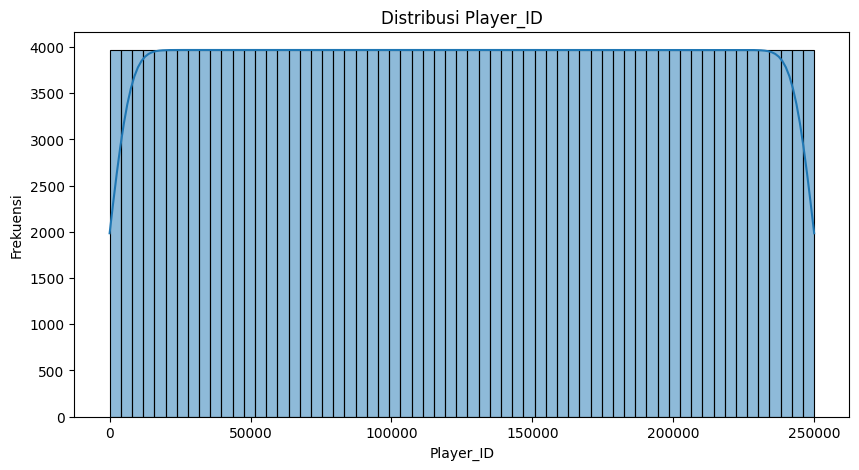

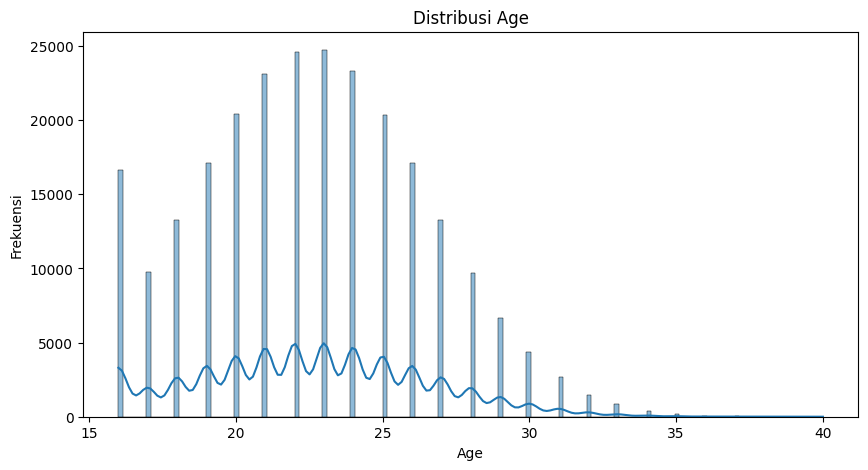

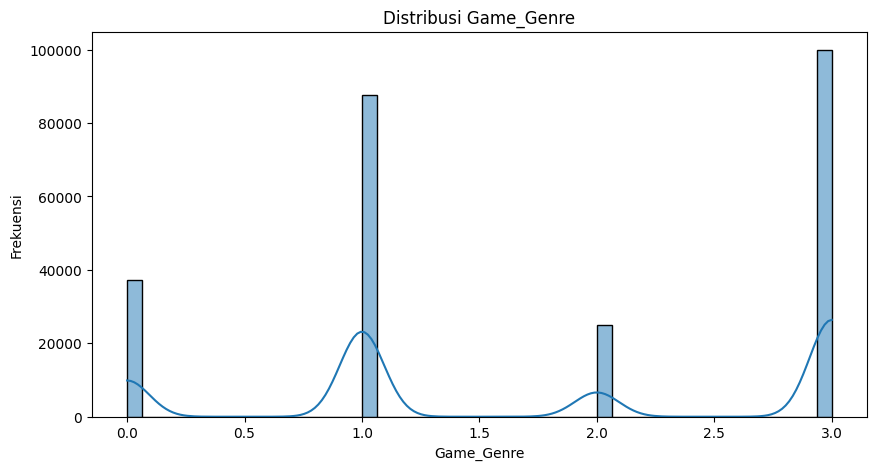

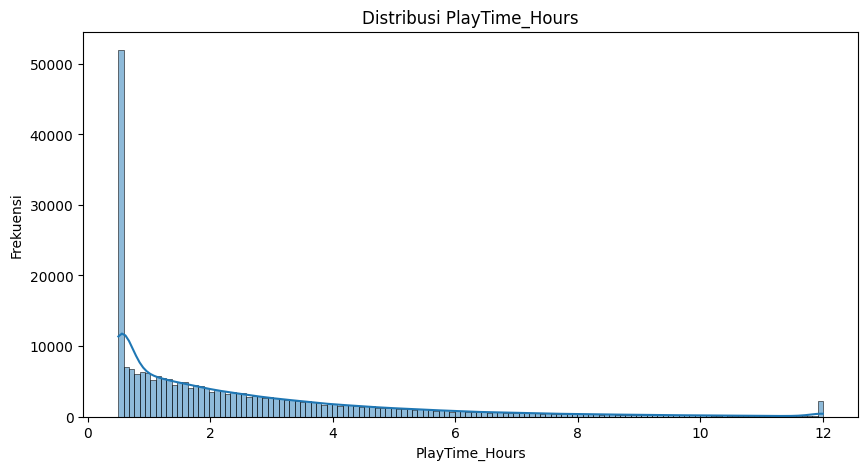

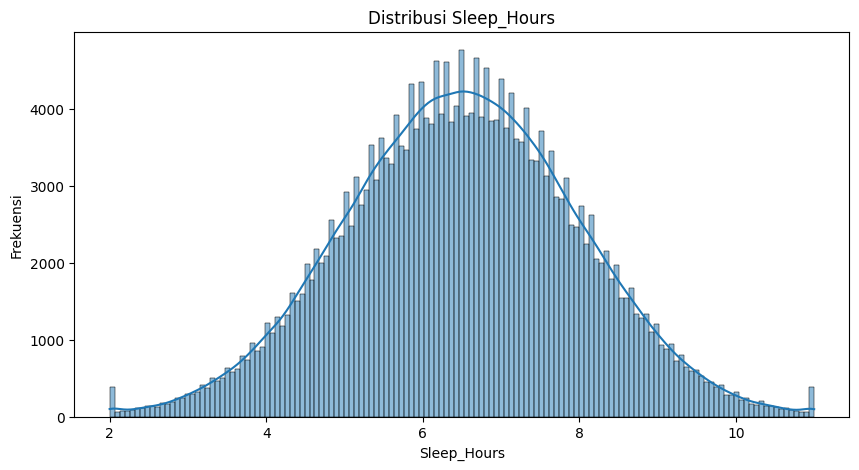

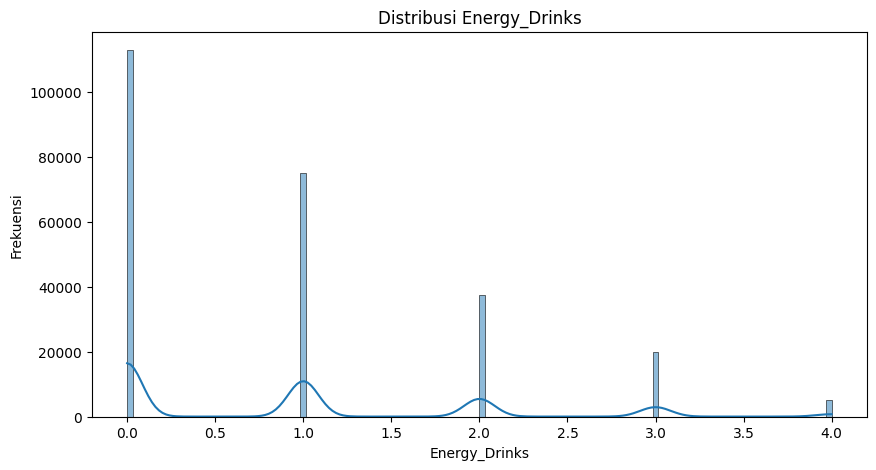

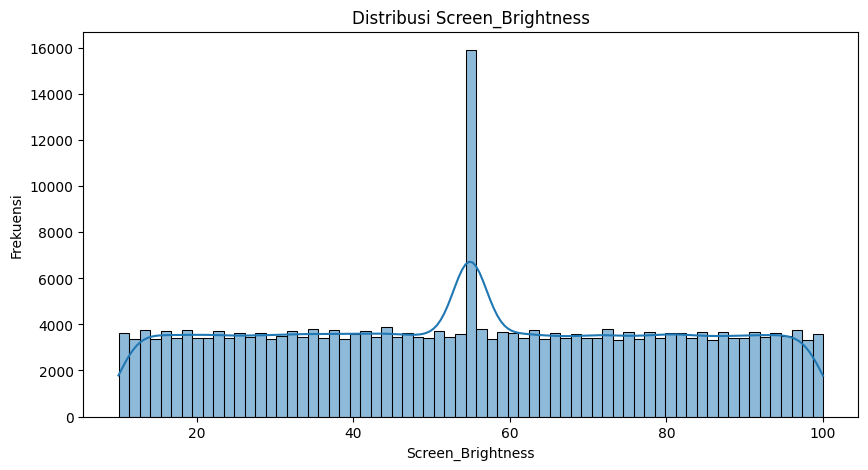

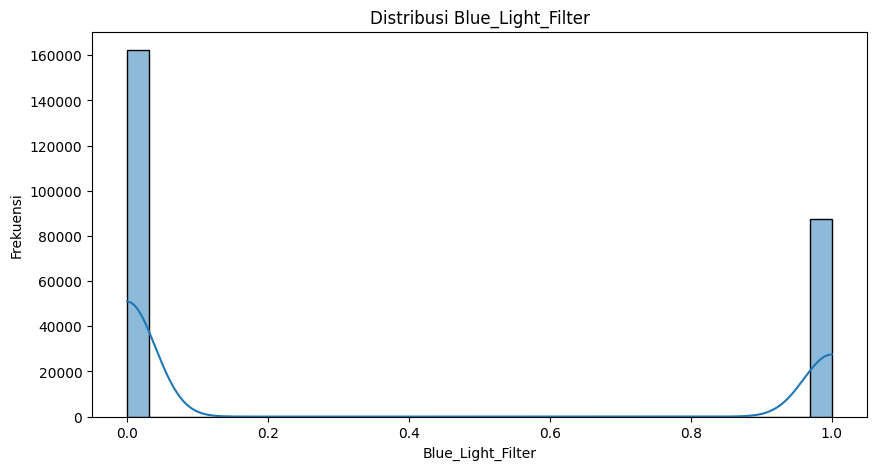

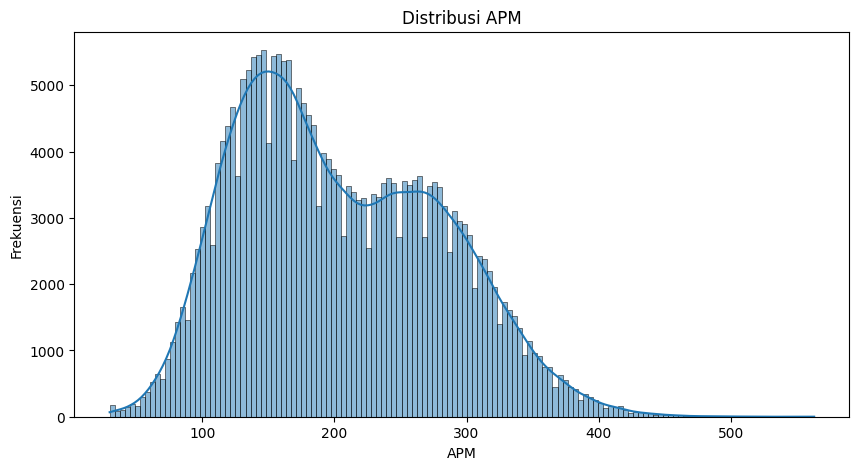

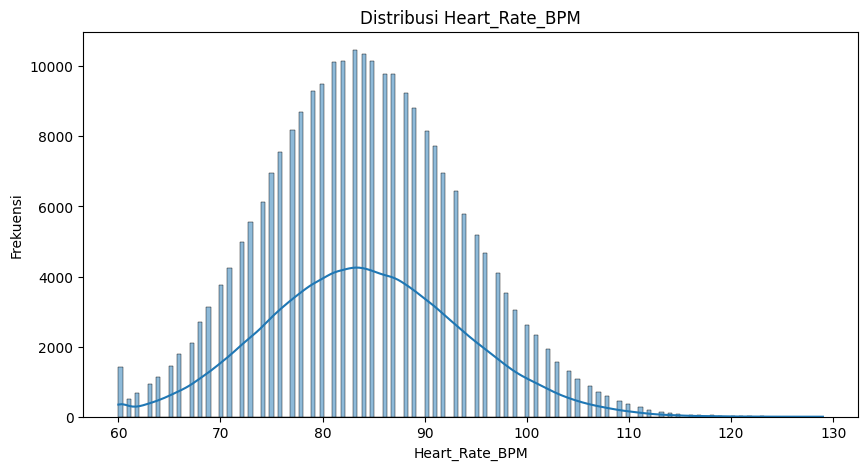

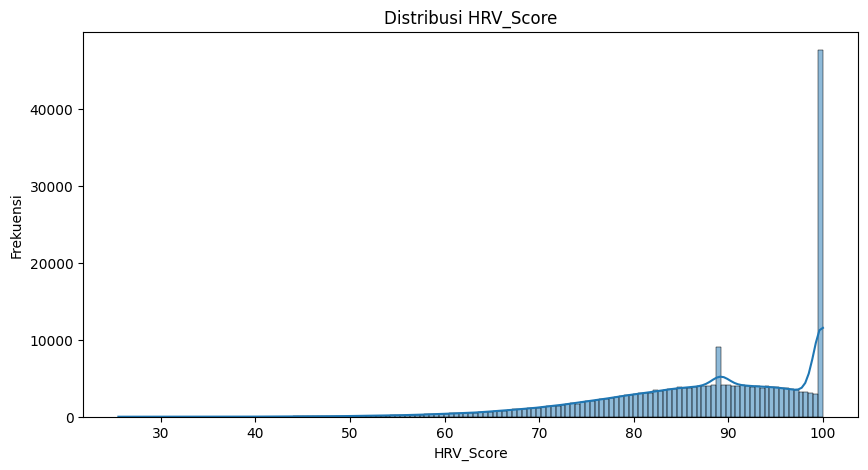

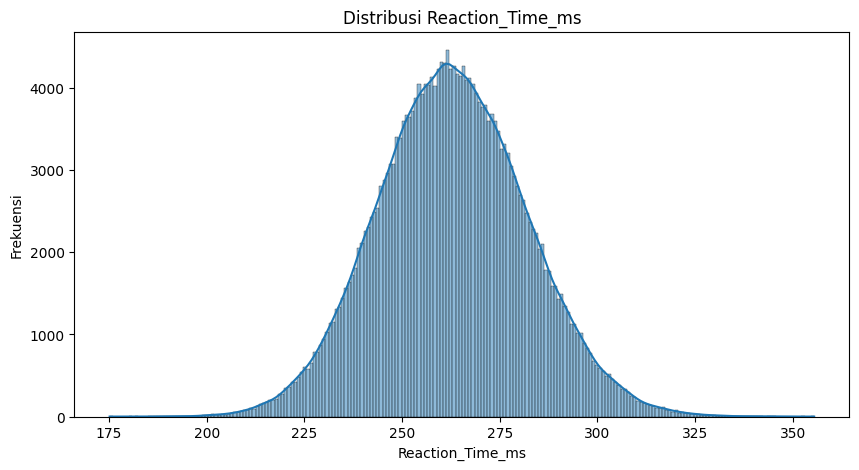

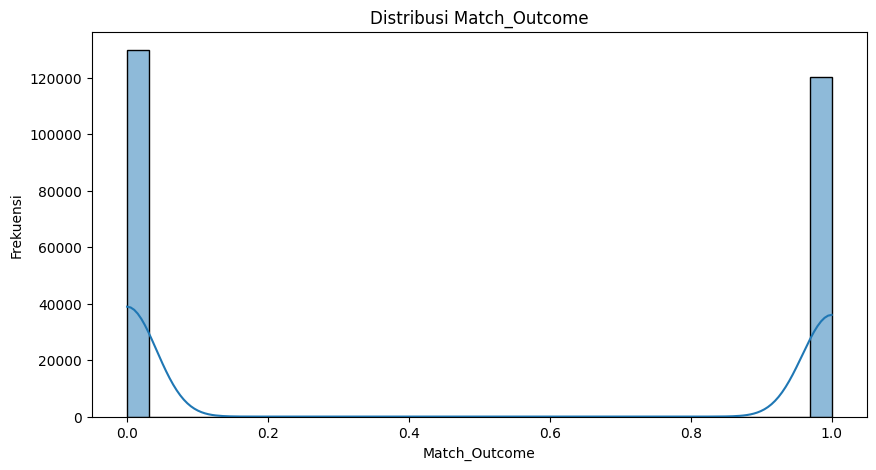

In [23]:
numeric_features = df.select_dtypes(include=['number']).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribusi {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frekuensi')
    plt.show()

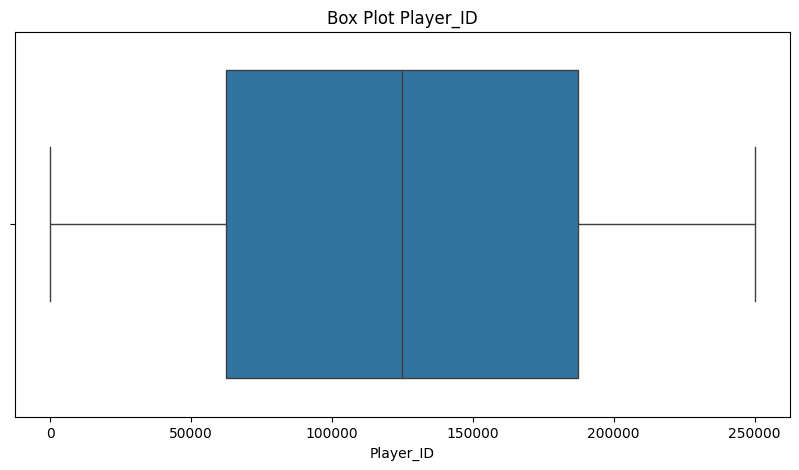

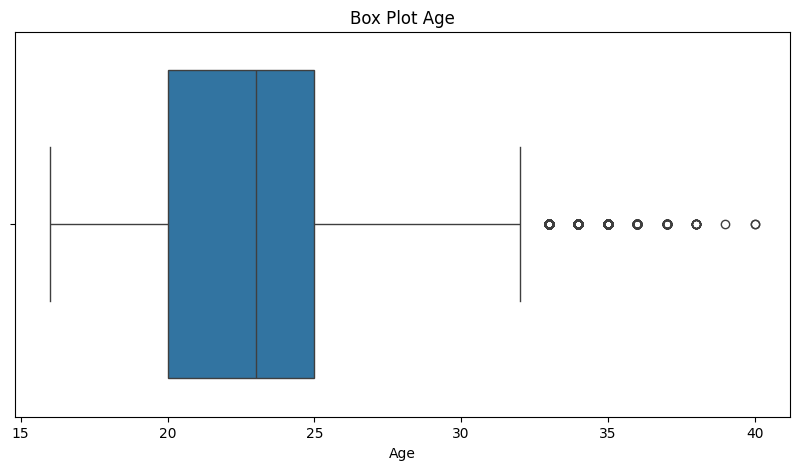

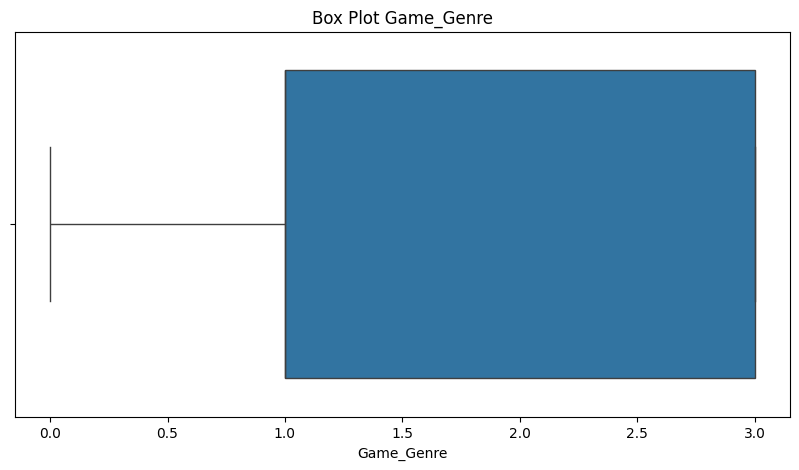

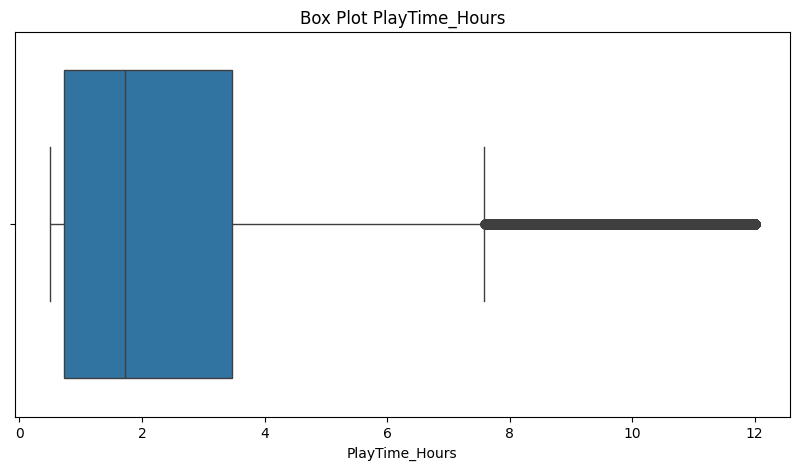

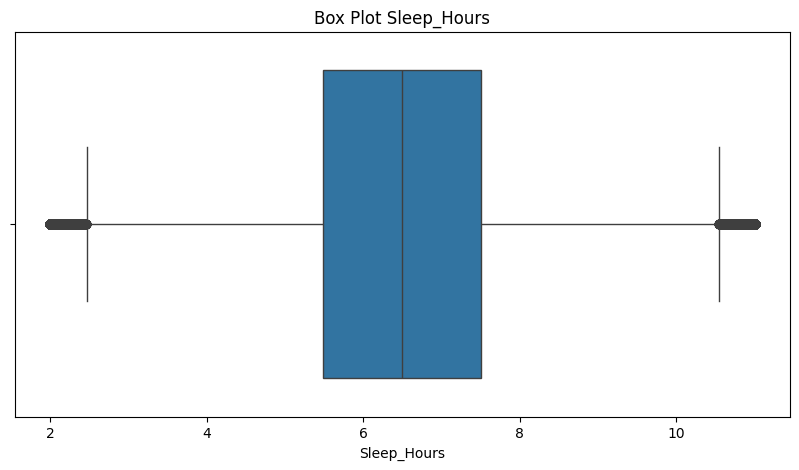

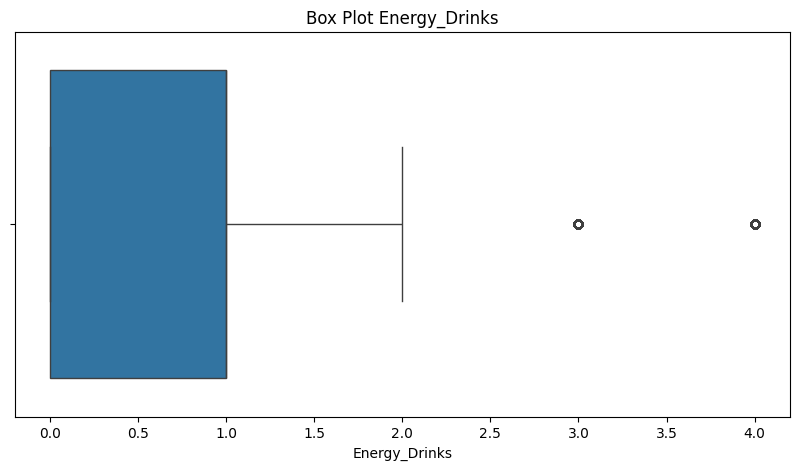

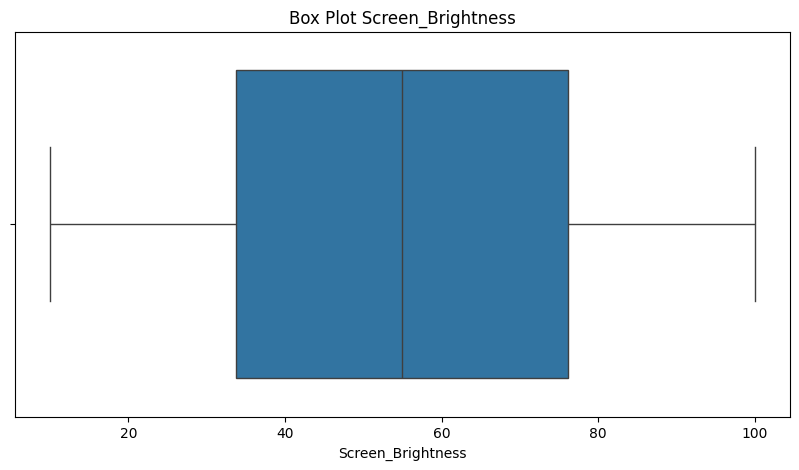

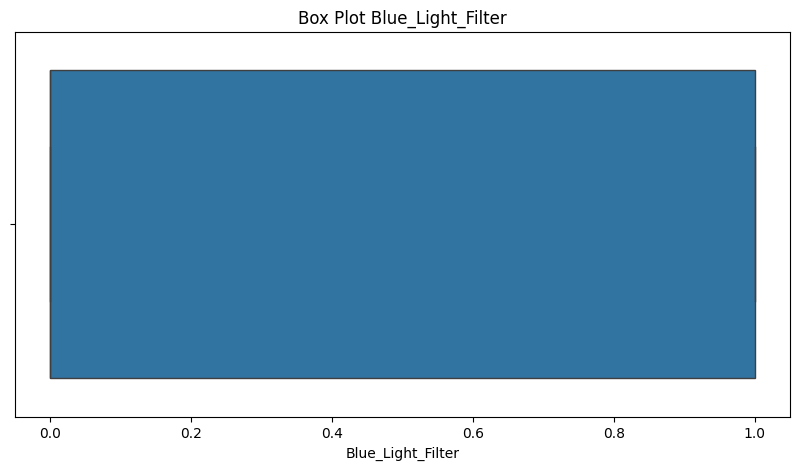

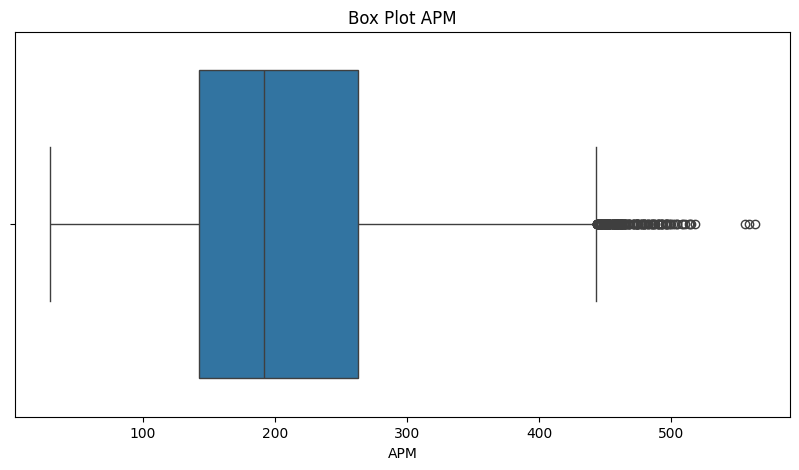

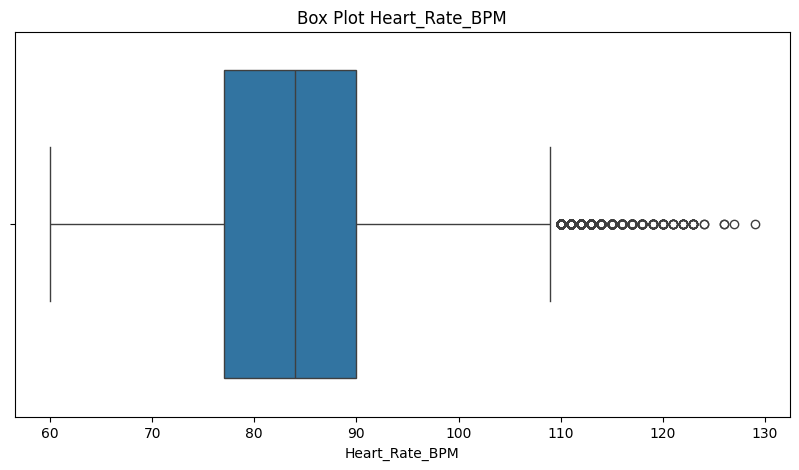

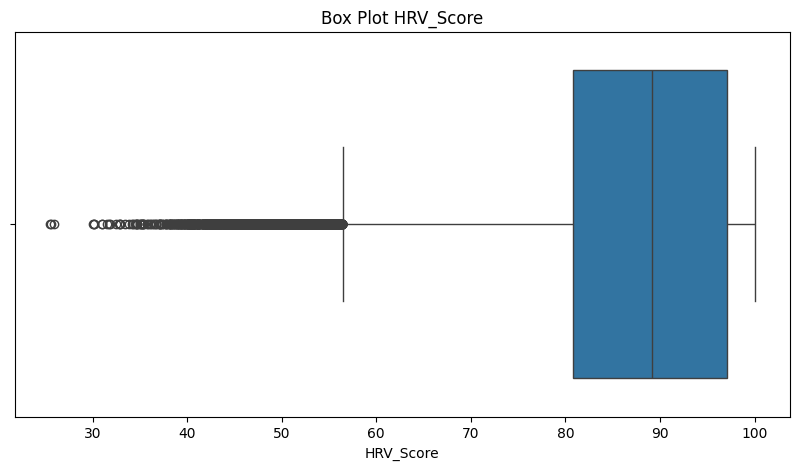

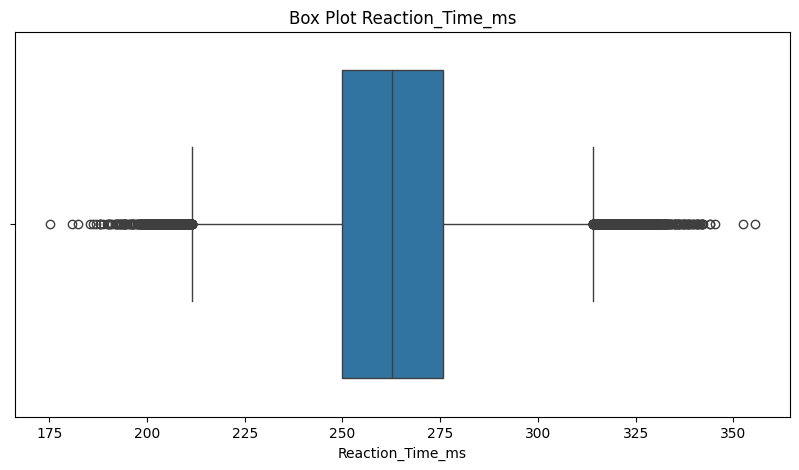

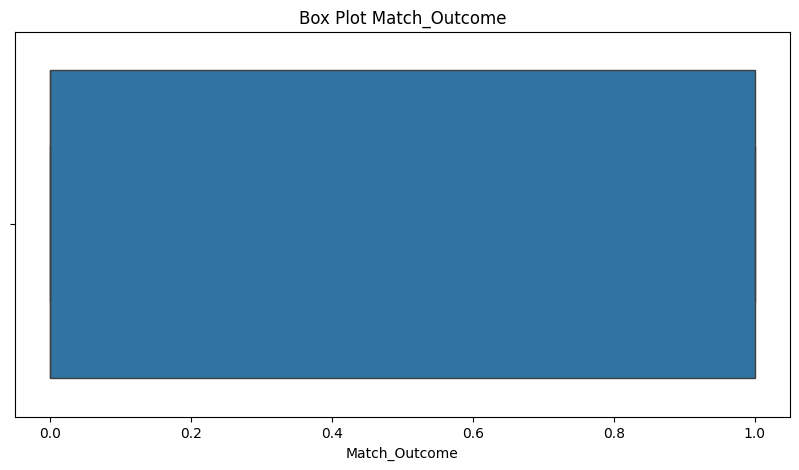

In [24]:
for feature in numeric_features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot {feature}')
    plt.show()

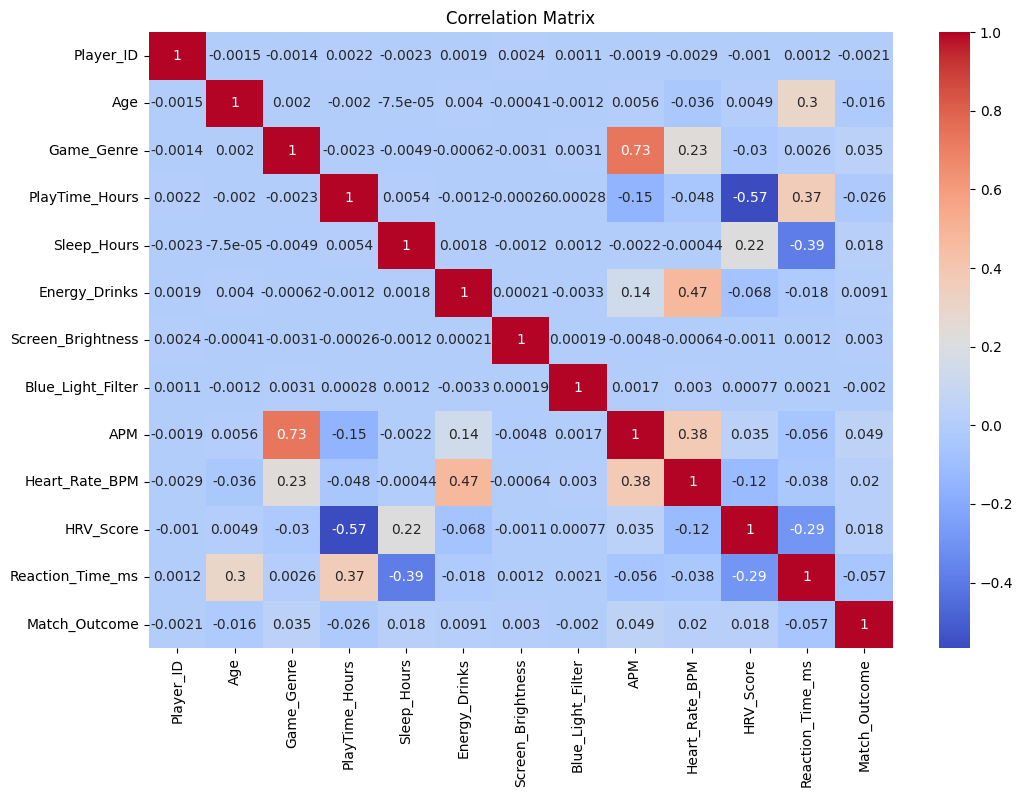

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

In [26]:
from sklearn.model_selection import train_test_split

# Fitur
X = df.drop(columns=['Player_ID', 'Match_Outcome'])

# Target
y = df['Match_Outcome']

# Split 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

print("Jumlah data:", len(X))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data: 250000
Jumlah data training: 200000
Jumlah data testing: 50000


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Player_ID          250000 non-null  int64  
 1   Age                250000 non-null  int64  
 2   Game_Genre         250000 non-null  int64  
 3   PlayTime_Hours     250000 non-null  float64
 4   Sleep_Hours        250000 non-null  float64
 5   Energy_Drinks      250000 non-null  int64  
 6   Screen_Brightness  250000 non-null  float64
 7   Blue_Light_Filter  250000 non-null  int64  
 8   APM                250000 non-null  int64  
 9   Heart_Rate_BPM     250000 non-null  int64  
 10  HRV_Score          250000 non-null  float64
 11  Reaction_Time_ms   250000 non-null  float64
 12  Match_Outcome      250000 non-null  int64  
dtypes: float64(5), int64(8)
memory usage: 24.8 MB


In [28]:
df.shape[0]

250000